In [2]:
from datasets import load_dataset
from transformers import AutoTokenizer, BertModel
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, Subset
from tqdm.auto import tqdm
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
from utils import save_checkpoint, load_checkpoint
import random


d:\anaconda3\envs\CS2109S\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
sst2_dataset = load_dataset("SetFit/sst2")

Repo card metadata block was not found. Setting CardData to empty.


In [4]:
model = BertModel.from_pretrained("bert-base-uncased")

In [5]:
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
# print(sst2_dataset)tr
# print(sst2_dataset['train'])
# print(sst2_dataset['train'][0])
# print(sst2_dataset['train']['text'])


In [6]:
train_text_lengths = [len(tokenizer.tokenize(text)) for text in sst2_dataset['train']['text']]

validation_text_lengths = [len(tokenizer.tokenize(text)) for text in sst2_dataset['validation']['text']]

max_train_length = max(train_text_lengths)
max_validation_length = max(validation_text_lengths)

In [7]:

import pathlib
EMBEDDING_TRAIN_SST2 = "../data/sst-2/embedding_train.pt"
EMBEDDING_VALIDATION_SST2 = "../data/sst-2/embedding_validation.pt"
train_texts = sst2_dataset['train']['text'][:500]
validation_texts = sst2_dataset['validation']['text'][:80]
sst2_train_embeddings = []
sst2_validation_embeddings = []
if pathlib.Path(EMBEDDING_TRAIN_SST2).is_file() and pathlib.Path(EMBEDDING_VALIDATION_SST2).is_file():
    print("Loading embeddings")
    sst2_train_embeddings = torch.load(EMBEDDING_TRAIN_SST2)
    sst2_validation_embeddings = torch.load(EMBEDDING_VALIDATION_SST2)
    
else:
    for text in tqdm(train_texts, desc="Embedding train SST2", total=len(train_texts)):
        tokenized_text = tokenizer(text, truncation=True, max_length=max_train_length, return_tensors="pt", padding="max_length")
        embedding = model(**tokenized_text).last_hidden_state
        sst2_train_embeddings.append(embedding)
    torch.save(sst2_train_embeddings, EMBEDDING_TRAIN_SST2)
        
    for text in tqdm(validation_texts, desc="Embedding train SST2", total=len(validation_texts)):
        tokenized_text = tokenizer(text, truncation=True, max_length=max_validation_length, return_tensors="pt", padding="max_length")
        embedding = model(**tokenized_text).last_hidden_state
        sst2_validation_embeddings.append(embedding)    
    torch.save(sst2_validation_embeddings, EMBEDDING_VALIDATION_SST2)


Loading embeddings


In [8]:
class SST2EmbedDataset(Dataset):
    def __init__(self, embeddings, labels):
        self.embeddings = embeddings
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        embedding = torch.tensor(self.embeddings[idx])
        label = torch.tensor(self.labels[idx])
        return embedding, label
    
sst2_embed_dataset_train = SST2EmbedDataset(sst2_train_embeddings, sst2_dataset['train']['label'][:500])
sst2_embed_train_dataloader = DataLoader(sst2_embed_dataset_train, batch_size=64, shuffle=True)

sst2_embed_dataset_validate = SST2EmbedDataset(sst2_validation_embeddings, sst2_dataset['validation']['label'][:80])
sst2_embed_validate_dataloader = DataLoader(sst2_embed_dataset_validate, batch_size=64, shuffle=False)
for x, y in sst2_embed_train_dataloader:
    print(x.shape, y.shape)
    break

torch.Size([64, 1, 78, 768]) torch.Size([64])


C:\Users\yyxxc\AppData\Local\Temp\ipykernel_29304\3943877874.py:10: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  embedding = torch.tensor(self.embeddings[idx])


In [9]:
class TextCNN(nn.Module):
    def __init__(self, embed_dim=768, num_classes=2, kernel_sizes=[2, 3, 4], num_filters=2):
        super(TextCNN, self).__init__()
        self.convs = nn.ModuleList([
            nn.Conv2d(1, num_filters, (k, embed_dim)) for k in kernel_sizes
        ])
        self.dropout = nn.Dropout(0.5)
        self.fc = nn.Linear(len(kernel_sizes) * num_filters, num_classes)
        
    def forward(self, x):
        conv_outputs = []
        for conv in self.convs:
            conv_output = F.relu(conv(x)) # [batch size, num_filters, seq_len - kernel_size + 1, 1]
            conv_output_pool = F.max_pool2d(conv_output, (conv_output.shape[2], 1))
            conv_outputs.append(conv_output_pool.squeeze(3).squeeze(2))
        output = torch.cat(conv_outputs, dim=1)
        output = self.dropout(output)
        output = self.fc(output)
        return output

In [10]:
def train_func_classification(model, criterion, optimizer, train_loader, validation_loader, epochs, record_checkpoints=None, save=True):
    train_losses = []
    accuracies = []
    checkpoints = []
    validation_losses = []
    
    for epoch in range(epochs):
        model.train()
        loss = 0.0
        for x_batch, y_batch in train_loader:
            optimizer.zero_grad()
            y_pred = model(x_batch)
            loss = criterion(y_pred, y_batch)
            loss.backward()
            optimizer.step()
            loss += loss.item()
            
        loss = loss / len(train_loader)
        train_losses.append(loss)
            
        model.eval()
        correct_count = 0
        validation_loss = 0.0
        for x_val_batch, y_val_batch in validation_loader:
            y_pred = model(x_val_batch)
            loss = criterion(y_pred, y_val_batch)
            validation_loss += loss.item()
            predictions = torch.argmax(y_pred, dim=-1)
            result = predictions == y_val_batch
            correct_count += result.sum()
            
        accuracy = (correct_count / len(validation_loader.dataset)).item()
        accuracies.append(accuracy)
        
        validation_loss = validation_loss / len(validation_loader)
        validation_losses.append(validation_loss)
        
        if save:
            print(f"Epoch: {epoch + 1}, Train Loss: {loss}, accuracy: {accuracy}")
            
            if record_checkpoints:
                if (epoch + 1) in record_checkpoints or (
                    epoch > 1 and accuracies[-1] - accuracies[-2] > 0.1) or (epoch + 1 == 115):
                    checkpoint_f = save_checkpoint(model, optimizer, epoch + 1, epochs, f"../checkpoint/{type(model).__name__}")
                    checkpoints.append(checkpoint_f)
            else:
                if ((epoch + 1) / epochs in [0.2, 0.4, 0.6, 0.8, 1.0]) or (
                    epoch > 1 and accuracies[-1] - accuracies[-2] > 0.1) or (epoch + 1 == 115):
                    checkpoint_f = save_checkpoint(model, optimizer, epoch + 1, epochs, filepath=f"../checkpoint/{type(model).__name__}")
                    checkpoints.append(checkpoint_f)
        
    epochs_range = range(1, epochs + 1)
    train_losses = [loss.detach().numpy() for loss in train_losses]
    if save:
        fig, ax1 = plt.subplots(figsize=(10, 5))
        ax1.plot(epochs_range, train_losses, label='Train Loss')
        ax1.plot(epochs_range, validation_losses, label='Validation Loss')
        ax1.set_xlabel('Epoch')
        ax1.set_ylabel('Loss')
        
        ax2 = ax1.twinx()
        ax2.plot(epochs_range, accuracies, label='Accuracy', color='r')
        ax2.set_ylabel('Accuracy')
        
        plt.title('Loss and Accuracy')
        fig.legend()
        plt.show()
    return model, checkpoints, train_losses, accuracies, validation_losses

In [11]:
for x, y in sst2_embed_train_dataloader:
    print(x.shape, y.shape)
    break

torch.Size([64, 1, 78, 768]) torch.Size([64])


C:\Users\yyxxc\AppData\Local\Temp\ipykernel_29304\3943877874.py:10: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  embedding = torch.tensor(self.embeddings[idx])


C:\Users\yyxxc\AppData\Local\Temp\ipykernel_11236\3943877874.py:10: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  embedding = torch.tensor(self.embeddings[idx])


Epoch: 1, Train Loss: 0.6914280652999878, accuracy: 0.550000011920929
Epoch: 2, Train Loss: 0.6904292106628418, accuracy: 0.5375000238418579
Epoch: 3, Train Loss: 0.6875203847885132, accuracy: 0.574999988079071
Checkpoint at 0.03 saved: ../checkpoint/TextCNN/TextCNN_epoch_3_0.03.pth
Epoch: 4, Train Loss: 0.6834856271743774, accuracy: 0.612500011920929
Epoch: 5, Train Loss: 0.6823478937149048, accuracy: 0.625
Epoch: 6, Train Loss: 0.680336594581604, accuracy: 0.625
Checkpoint at 0.06 saved: ../checkpoint/TextCNN/TextCNN_epoch_6_0.06.pth
Epoch: 7, Train Loss: 0.6794765591621399, accuracy: 0.612500011920929
Epoch: 8, Train Loss: 0.6776975393295288, accuracy: 0.625
Epoch: 9, Train Loss: 0.6798803210258484, accuracy: 0.550000011920929
Epoch: 10, Train Loss: 0.6736096739768982, accuracy: 0.6000000238418579
Checkpoint at 0.1 saved: ../checkpoint/TextCNN/TextCNN_epoch_10_0.1.pth
Epoch: 11, Train Loss: 0.6675921082496643, accuracy: 0.675000011920929
Epoch: 12, Train Loss: 0.6606835722923279, ac

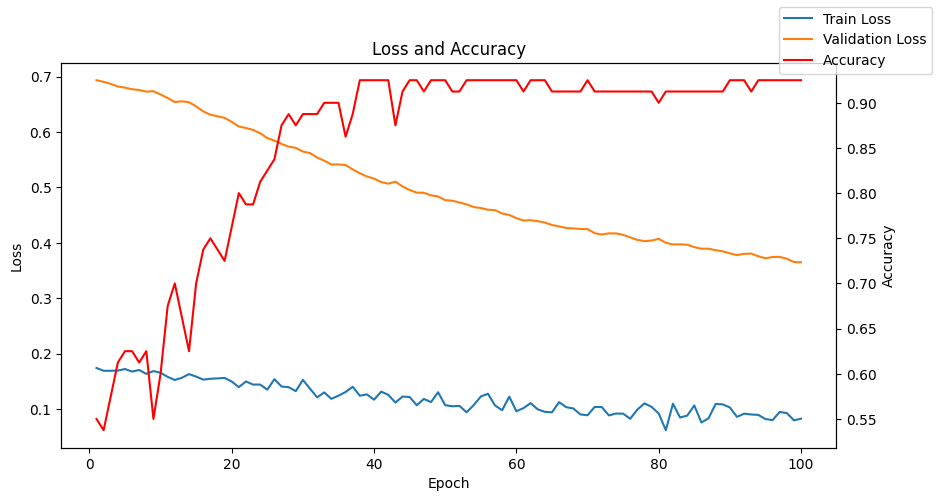

In [ ]:
model = TextCNN(768, 2)
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)
model, checkpoints, train_losses, accuracies, validation_losses = train_func_classification(model, nn.CrossEntropyLoss(), optimizer, sst2_embed_train_dataloader, sst2_embed_validate_dataloader, 100, 
                                                 [3, 6, 10, 13, 16, 20, 25, 40, 60, 80, 100])

In [12]:
checkpoints = ['../checkpoint/TextCNN/TextCNN_epoch_3_0.03.pth',
 '../checkpoint/TextCNN/TextCNN_epoch_5_0.05.pth',
 '../checkpoint/TextCNN/TextCNN_epoch_6_0.06.pth',
 '../checkpoint/TextCNN/TextCNN_epoch_10_0.1.pth',
 '../checkpoint/TextCNN/TextCNN_epoch_13_0.13.pth',
 '../checkpoint/TextCNN/TextCNN_epoch_16_0.16.pth',
 '../checkpoint/TextCNN/TextCNN_epoch_20_0.2.pth',
 '../checkpoint/TextCNN/TextCNN_epoch_25_0.25.pth',
 '../checkpoint/TextCNN/TextCNN_epoch_40_0.4.pth',
 '../checkpoint/TextCNN/TextCNN_epoch_60_0.6.pth',
 '../checkpoint/TextCNN/TextCNN_epoch_80_0.8.pth',
 '../checkpoint/TextCNN/TextCNN_epoch_100_1.0.pth']

In [13]:
import os
import sys
module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)
from torch_influence.base import BaseObjective
from torch_influence.modules import CGInfluenceModule, LiSSAInfluenceModule, AutogradInfluenceModule

def calculate_influence_score_nn(
    traindata: DataLoader, 
    testdata: DataLoader, 
    model, 
    criterion,
    device,
    epochs=-1,
    train_func=None,
    per_point=-1, 
    appro="cg"
    ):
    """
    Calculate influence score for each training data point
    Parameters
    ----------
    traindata: train data loader
    testdata: test data loader
    model: nn.Module
    per_point: if >= 0: return instance score for specific test point; else return instance score for test sets
    Returns
    -------

    """

    # initialize the model and optimizer
    trainidx = len(traindata.dataset)
    testidx = len(testdata.dataset)

    class NNObjective(BaseObjective):
        
        # batch: Dataset
        def train_outputs(self, model, batch):
            inputs, _ = batch
            inputs = inputs
            inputs = inputs.to(device, dtype=torch.float)
            return model(inputs)

        def train_loss_on_outputs(self, outputs, batch):
            _, labels = batch
            labels = labels
            labels = labels.to(device)
            return criterion(outputs, labels)

        def train_regularization(self, params):
            return 0

        # training loss by default taken to be
        # train_loss_on_outputs + train_regularization

        def test_loss(self, model, params, batch):
            inputs, labels = batch
            inputs = inputs.to(device, dtype=torch.float)
            labels = labels.to(device)
            return criterion(model(inputs), labels)
        
    if train_func != None:
        model, _, val_losses = train_func(
            model = model,
            criterion = criterion,
            optimizer = torch.optim.Adam(model.parameters(), lr=0.0001),
            train_loader = traindata,
            validation_loader = testdata,
            epochs = epochs,
            )
    
    print("Start calculating influence scores...")

    if appro == "lissa":
        print("LissaInfluenceModule")
        module = LiSSAInfluenceModule(
            model=model,
            objective=NNObjective(),
            train_loader=traindata,
            test_loader=testdata,
            device=device,
            damp=0.003,
            repeat=1,
            depth=2500,
            scale=1e4,
        )
    elif appro == "cg":
        print("CGInfluenceModule")
        module = CGInfluenceModule(
            model=model,
            objective=NNObjective(),
            train_loader=traindata,
            test_loader=testdata,
            device=device,
            damp=0.003,
            atol=1e-8,
            maxiter=1000,
        )
    elif appro == "autograd":
        print("AutogradInfluenceModule")
        module = AutogradInfluenceModule(
            model=model,
            objective=NNObjective(),
            train_loader=traindata,
            test_loader=testdata,
            device=device,
            damp=0.003
        )

    print(f"train data size: {len(traindata.dataset)}")
    print(f"test data size: {len(testdata.dataset)}")
    if train_func != None:
        print(f"model performance validation loss / accuracy: {val_losses[-1]}")
    
    if per_point >= 0:
        scores = module.influences(np.arange(trainidx),  np.array([per_point])).cpu().numpy().reshape(-1)
    else:
        scores = module.influences(np.arange(trainidx), np.arange(testidx)).cpu().numpy().reshape(-1)
    return scores

def influence_at_checkpoints(traindata, testdata, model, optimizer,
                             criterion, checkpoints, device, per_point=-1, appro="cg"):
    scores = []
    for checkpoint in tqdm(checkpoints, desc=f"Calculating influence scores"):
        model, optimizer, _, completion_rate = load_checkpoint(model, optimizer, checkpoint)
        print(f"completion_rate: {completion_rate}" )
        score = calculate_influence_score_nn(traindata, testdata, model, criterion, device, per_point=per_point, appro=appro)
        scores.append(score)
    return scores

In [ ]:
model = TextCNN(768, 2)
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)
sst2_influences = influence_at_checkpoints(sst2_embed_train_dataloader, sst2_embed_validate_dataloader, model, optimizer,
                                           nn.CrossEntropyLoss(), checkpoints, "cpu", appro="lissa")

Calculating influence scores:   0%|          | 0/12 [00:00<?, ?it/s]

C:\Users\yyxxc\AppData\Local\Temp\ipykernel_11236\3943877874.py:10: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  embedding = torch.tensor(self.embeddings[idx])


Checkpoint loaded at epoch 3 with completion rate 0.03
completion_rate: 0.03
Start calculating influence scores...
LissaInfluenceModule
train data size: 500
test data size: 80
Calculating stest...


Calculating influence scores:   8%|▊         | 1/12 [07:36<1:23:45, 456.85s/it]

Checkpoint loaded at epoch 5 with completion rate 0.05
completion_rate: 0.05
Start calculating influence scores...
LissaInfluenceModule
train data size: 500
test data size: 80
Calculating stest...


...

Calculating influence scores:  83%|████████▎ | 10/12 [1:16:26<15:15, 457.98s/it]

Checkpoint loaded at epoch 80 with completion rate 0.8
completion_rate: 0.8
Start calculating influence scores...
LissaInfluenceModule
train data size: 500
test data size: 80
Calculating stest...


Calculating influence scores:  92%|█████████▏| 11/12 [1:24:05<07:38, 458.32s/it]

Checkpoint loaded at epoch 100 with completion rate 1.0
completion_rate: 1.0
Start calculating influence scores...
LissaInfluenceModule
train data size: 500
test data size: 80
Calculating stest...


Calculating influence scores: 100%|██████████| 12/12 [1:31:42<00:00, 458.52s/it]


In [ ]:
torch.save(sst2_influences, "../influences/sst2/sst2_influences.pt")
torch.save(accuracies, "../influences/sst2/sst2_accuracies.pt")
torch.save(train_losses, "../influences/sst2/sst2_train_losses.pt")
torch.save(validation_losses, "../influences/sst2/sst2_validation_losses.pt")

In [14]:
sst2_influences = torch.load("../influences/sst2/sst2_influences.pt")
accuracies = torch.load("../influences/sst2/sst2_accuracies.pt")
train_losses = torch.load("../influences/sst2/sst2_train_losses.pt")
validation_losses = torch.load("../influences/sst2/sst2_validation_losses.pt")

In [15]:
checkpoint_labels = np.array([3, 5, 6, 10, 13, 16, 20, 25, 40, 60, 80, 100])
x_vals = list(range(1, 101))

In [16]:
def top_last_influences(ckpt_influences, train_embeds, num_per_row=10, descending=True):
    top_inf_texts = []
    for influences in ckpt_influences:
        sorted_influences = torch.argsort(torch.from_numpy(influences), descending=descending)
        top_indexes = sorted_influences[:num_per_row]
        top_influential_train_data = [(train_embeds[index][0].detach().numpy().squeeze(0), train_embeds[index][1]) for index in top_indexes]
        top_inf_texts.append(top_influential_train_data)
    return top_inf_texts

def random_idx(checkpoint_influences, dataset, num_data, p):
    checkpoints_indices = []
    for _ in checkpoint_influences:
        num_select = int(p * num_data)
        indices = list(np.arange(len(dataset)))
        random_indices = random.sample(indices, num_select)
        checkpoints_indices.append(random_indices)
    return checkpoints_indices
test = top_last_influences(sst2_influences, sst2_embed_dataset_train, num_per_row=10, descending=True)
print(test[0][0][0].shape)

(78, 768)


C:\Users\yyxxc\AppData\Local\Temp\ipykernel_29304\3943877874.py:10: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  embedding = torch.tensor(self.embeddings[idx])


In [30]:
# Validate Influence Function
def random_idx(checkpoint_influences, dataset, num_data, p):
    checkpoints_indices = []
    for _ in checkpoint_influences:
        num_select = int(p * num_data)
        indices = list(np.arange(len(dataset)))
        random_indices = random.sample(indices, num_select)
        checkpoints_indices.append(random_indices)
    return checkpoints_indices

p = 0.05
num_data = len(sst2_embed_dataset_train)
random_indices = random_idx(sst2_influences, sst2_embed_dataset_train, num_data, 1 - p)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def validate_influence(influences, train_dataset, test_dataloader, model_class, criterion, device, checkpoints, checkpoint_labels, p):
    # top_ckpts_embeds = top_last_influences(influences, train_dataset, int(p*num_data))
    validate_accuracies = []
    validate_train_losses = []
    validate_validation_losses = []
    rand_validate_accuracies = []
    rand_validate_train_losses = []
    rand_validate_validation_losses = []
    
    for i in tqdm(range(len(checkpoints)), desc=f"Validating influences"):
        sorted_influences = torch.argsort(torch.from_numpy(influences[i]), descending=True)
        top_indexes = sorted_influences[:int(p*num_data)]
        filtered_indices = [i for i in list(range(len(train_dataset))) if i not in top_indexes]
        residual_train_dataset = Subset(train_dataset, filtered_indices)
        residual_dataloader = DataLoader(residual_train_dataset, batch_size=20, shuffle=True)
        
        random_dataset = Subset(train_dataset, random_indices[i])
        random_dataloader = DataLoader(random_dataset, batch_size=64, shuffle=True)
        
        optimizer = torch.optim.Adam(model_class().parameters(), lr=0.0001)
        epochs = checkpoint_labels[i]
        model = model_class().to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)
        _, _, val_train_losses, val_accuracies, val_validation_losses = train_func_classification(
            model, criterion, optimizer, residual_dataloader, test_dataloader, epochs, save=False)
        model = model_class().to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)
        _, _, rand_train_losses, rand_accuracies, rand_validation_losses = train_func_classification(
            model, criterion, optimizer, random_dataloader, test_dataloader, epochs, save=False)
        
        validate_train_losses.append(val_train_losses)
        validate_accuracies.append(val_accuracies)
        validate_validation_losses.append(val_validation_losses)
        rand_validate_validation_losses.append(rand_validation_losses)
        rand_validate_accuracies.append(rand_accuracies)
        rand_validate_train_losses.append(rand_train_losses)
    return validate_train_losses, validate_accuracies, validate_validation_losses, rand_validate_train_losses, rand_validate_accuracies, rand_validate_validation_losses

validate_train_losses, validate_accuracies, validate_validation_losses, rand_validate_train_losses, rand_validate_accuracies, rand_validate_validation_losses = validate_influence(sst2_influences, sst2_embed_dataset_train, sst2_embed_validate_dataloader, TextCNN, nn.CrossEntropyLoss(), device, checkpoints, checkpoint_labels, p)

Validating influences:   0%|          | 0/12 [00:00<?, ?it/s]C:\Users\yyxxc\AppData\Local\Temp\ipykernel_29304\3943877874.py:10: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  embedding = torch.tensor(self.embeddings[idx])
Validating influences: 100%|██████████| 12/12 [06:15<00:00, 31.32s/it]


In [31]:
torch.save(validate_train_losses, "../influences/sst2/sst2_validate_train_losses.pt")
torch.save(validate_accuracies, "../influences/sst2/sst2_validate_accuracies.pt")
torch.save(validate_validation_losses, "../influences/sst2/sst2_validate_validation_losses.pt")
torch.save(rand_validate_accuracies, "../influences/sst2/sst2_rand_validate_accuracies.pt")
torch.save(rand_validate_train_losses, "../influences/sst2/sst2_rand_validate_train_losses.pt")
torch.save(rand_validate_validation_losses, "../influences/sst2/sst2_rand_validate_validation_losses.pt")

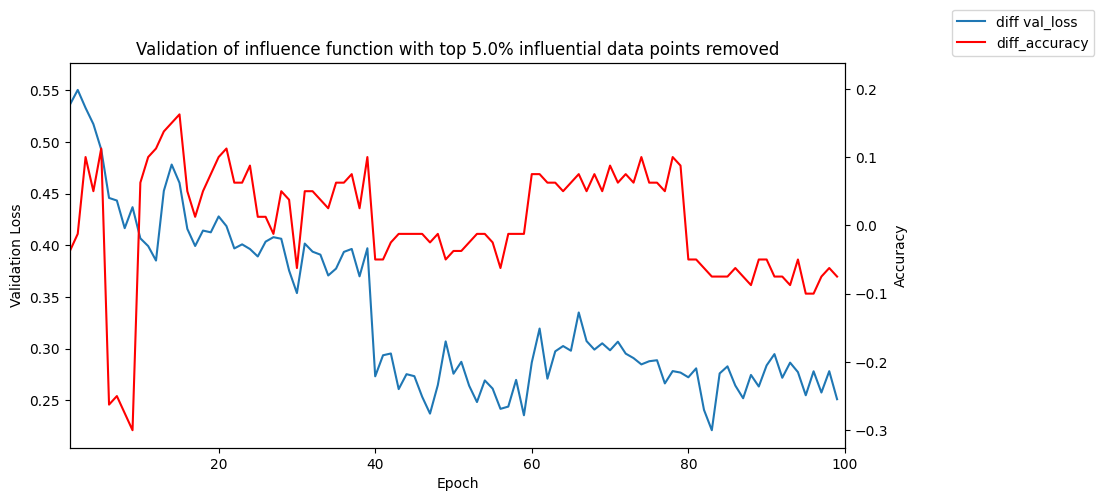

In [32]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))
def concat_ckpt_metrics(metrics, ckpt_labels):
    integrate_metrics = []
    for i, metric in enumerate(metrics):
        prev_ckpt = ckpt_labels[i-1] if i > 0 else 0
        integrate_metrics.append(metric[prev_ckpt:])
    return np.concatenate(integrate_metrics)

diff_val_loss = concat_ckpt_metrics(validate_validation_losses, checkpoint_labels) - concat_ckpt_metrics(rand_validate_train_losses, checkpoint_labels) # suppose positive
diff_accuracy = concat_ckpt_metrics(rand_validate_accuracies, checkpoint_labels) - concat_ckpt_metrics(validate_accuracies, checkpoint_labels) # suppose positive

ax1.plot(diff_val_loss, label='diff val_loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Validation Loss')

ax2 = ax1.twinx()
ax2.plot(diff_accuracy, label='diff_accuracy', color='r')
ax2.set_ylabel('Accuracy')
plt.title(f'Validation of influence function with top {p*100}% influential data points removed')
fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

C:\Users\yyxxc\AppData\Local\Temp\ipykernel_29304\3943877874.py:10: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  embedding = torch.tensor(self.embeddings[idx])
C:\Users\yyxxc\AppData\Local\Temp\ipykernel_29304\3943877874.py:10: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  embedding = torch.tensor(self.embeddings[idx])
C:\Users\yyxxc\AppData\Local\Temp\ipykernel_29304\3943877874.py:10: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  embedding = torch.tensor(self.embeddings[idx])


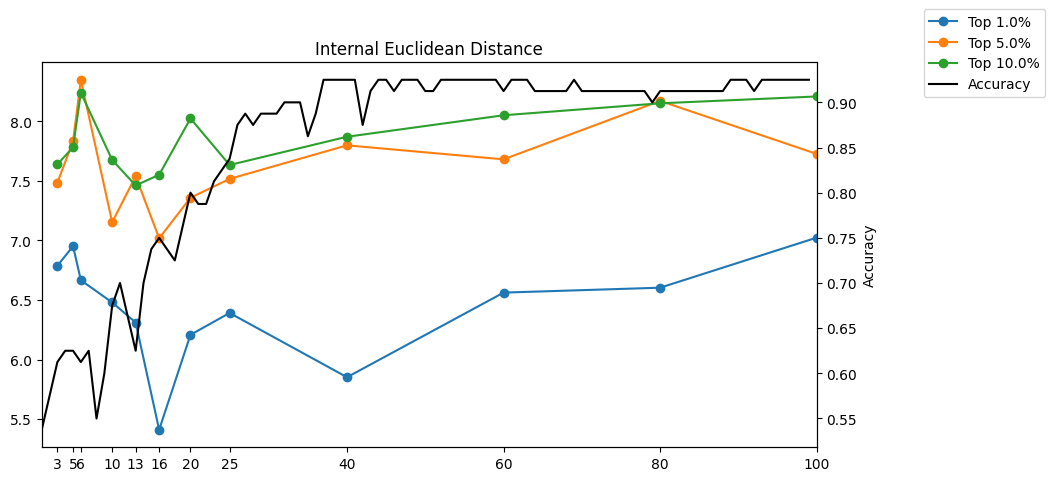

In [33]:
from sklearn.metrics.pairwise import euclidean_distances

# distance between text embeddings of within a single checkpoint
def calc_inter_dist(embeds):
    distances = euclidean_distances(embeds, embeds)
    mean_distance = np.mean(distances)
    return mean_distance


def calc_external_dist(inf_embeds, other_embeds):
    distances = euclidean_distances(inf_embeds, other_embeds)
    mean_distance = np.mean(distances)
    return mean_distance


fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))
for p in [0.01, 0.05, 0.1]:
    int_distances = []
    top_inf_embeds = top_last_influences(sst2_influences, sst2_embed_dataset_train, int(p*num_data))
    for ckpt, ckpt_embeds in enumerate(top_inf_embeds):
        embed_inputs = np.array([embed[0] for embed in ckpt_embeds])
        embed_inputs = embed_inputs[:, 0, :]
        mean_dist = calc_inter_dist(embed_inputs)
        int_distances.append(mean_dist)
    ax1.plot(checkpoint_labels, int_distances, 'o-', label=f"Top {p*100}%")
plt.title("Internal Euclidean Distance")
ax1.set_xticks(checkpoint_labels)

ax2 = ax1.twinx()
ax2.set_ylabel("Accuracy")
ax2.plot(accuracies, label="Accuracy", color='k')
fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

Select top 1% influential points as it has clearer trends.

C:\Users\yyxxc\AppData\Local\Temp\ipykernel_29304\3943877874.py:10: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  embedding = torch.tensor(self.embeddings[idx])


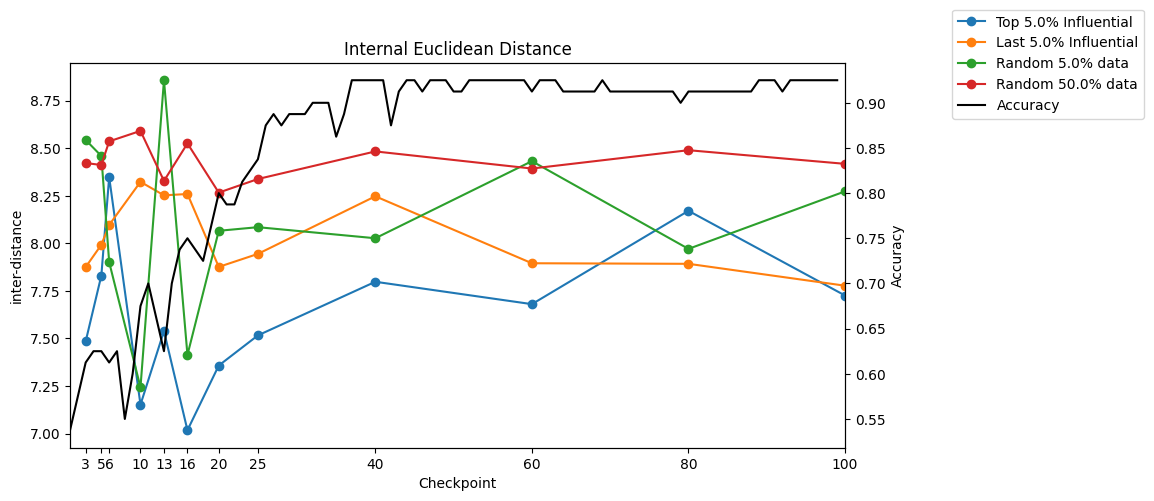

In [34]:
# from utils import random_p_data

p = 0.05
def random_p_data(checkpoint_influences, train_dataset, num_data, p=p):
    checkpoints_data = []
    for _ in checkpoint_influences:
        num_select = int(p * num_data)
        random_data = random.sample(list(train_dataset), num_select)
        random_data = [(data[0].detach().numpy().squeeze(0), data[1]) for data in random_data]
        checkpoints_data.append(random_data)
    return checkpoints_data
random_embeds = random_p_data(sst2_influences, sst2_embed_dataset_train, num_data, p)
random_embeds_large = random_p_data(sst2_influences, sst2_embed_dataset_train, num_data, p*10)
last_ckpts_embeds = top_last_influences(sst2_influences, sst2_embed_dataset_train, int(p*num_data), False)
top_ckpts_embeds = top_last_influences(sst2_influences, sst2_embed_dataset_train, int(num_data*p))

fig, ax1 = plt.subplots(figsize=(10, 5))
# ax2 = ax1.twinx()
ax1.set_xlim(min(x_vals), max(x_vals))
topinf_int_distances = []
for i in range(len(top_ckpts_embeds)):
    # each checkpoint
    embeds = np.array([embed[0] for embed in top_ckpts_embeds[i]])[:, 0, :]
    repre = calc_inter_dist(embeds)
    topinf_int_distances.append(repre)
ax1.plot(checkpoint_labels, topinf_int_distances, 'o-', label=f"Top {p*100}% Influential")

lastinf_int_distances = []
for i in range(len(last_ckpts_embeds)):
    # each checkpoint    
    embeds = np.array([embed[0] for embed in last_ckpts_embeds[i]])[:, 0, :]
    repre = calc_inter_dist(embeds)
    lastinf_int_distances.append(repre)
ax1.plot(checkpoint_labels, lastinf_int_distances, 'o-', label=f"Last {p*100}% Influential")

rand_int_distances = []
for i in range(len(checkpoints)):
    embeds = np.array([embed[0] for embed in random_embeds[i]])[:, 0, :]
    repre = calc_inter_dist(embeds)
    rand_int_distances.append(repre)
ax1.plot(checkpoint_labels, rand_int_distances, 'o-', label=f"Random {p*100}% data")

rand_int_distances = []
for i in range(len(checkpoints)):
    embeds = np.array([embed[0] for embed in random_embeds_large[i]])[:, 0, :]
    repre = calc_inter_dist(embeds)
    rand_int_distances.append(repre)
ax1.plot(checkpoint_labels, rand_int_distances, 'o-', label=f"Random {p*1000}% data")

ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("inter-distance")
ax1.set_xticks(checkpoint_labels)
ax2 = ax1.twinx()
ax2.set_ylabel("Accuracy")
ax2.plot(accuracies, label="Accuracy", color='k')

fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.title("Internal Euclidean Distance")
plt.show()

Suggest use random 50% in replacement of random 5% due to its stability

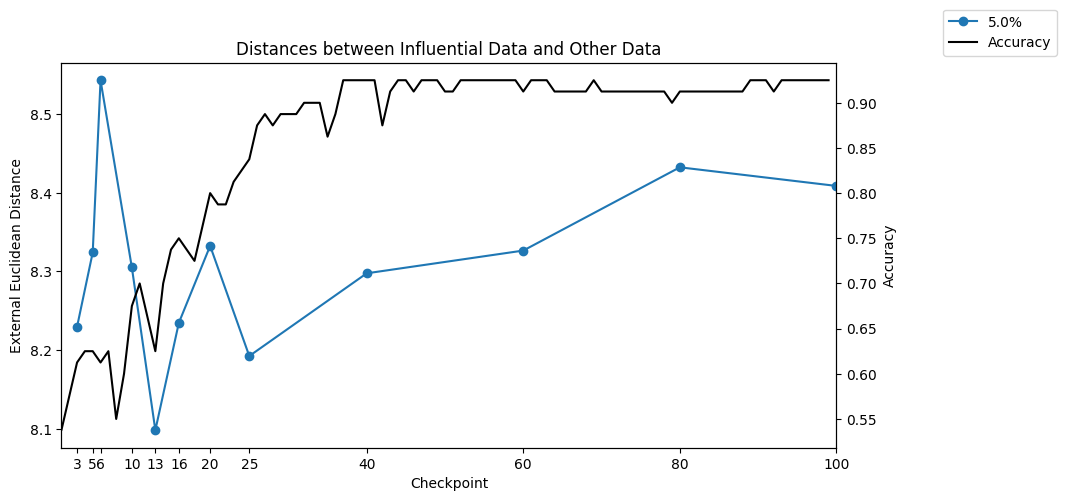

In [35]:
# Euclidean distance from influential points to other points
# random_embeds = random_p_data(sst2_influences, sst2_embed_dataset_train, num_data, p)

fig, ax1 = plt.subplots(figsize=(10, 5))
# ax2 = ax1.twinx()
plt.title("Distances between Influential Data and Other Data")
distances = []
for i, ckpt_embeds in enumerate(top_inf_embeds):
    inf_embeds =  np.array([embed[0] for embed in ckpt_embeds])[:, 0, :]
    rand_embeds =  np.array([embed[0] for embed in random_embeds_large[i]])[:, 0, :]
    mean_dist = calc_external_dist(inf_embeds, rand_embeds)
    distances.append(mean_dist)
ax1.set_xlim(min(x_vals), max(x_vals))
ax1.plot(checkpoint_labels, distances, 'o-', label=f"{p * 100}%")
ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("External Euclidean Distance")
ax1.set_xticks(checkpoint_labels)
ax2 = ax1.twinx()
ax2.set_ylabel("Accuracy")
ax2.plot(accuracies, label="Accuracy", color='k')

fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

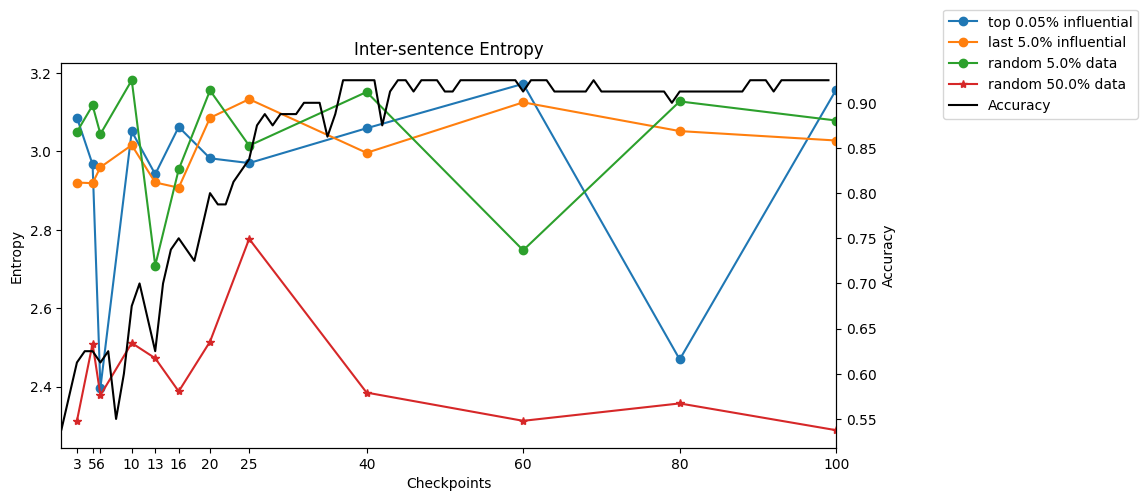

In [36]:
from scipy.spatial.distance import pdist
from scipy.stats import entropy

def inter_sentence_entropy(sentence_embeds):
    pairwise_distances = pdist(sentence_embeds, metric='cosine')
    distance_probs, _ = np.histogram(pairwise_distances, bins=30, density=True)
    distance_probs = distance_probs / np.sum(distance_probs)
    pairwise_entropy = entropy(distance_probs)
    return pairwise_entropy

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))
# ax2 = ax1.twinx()
topinf_entropies = []
for ckpt, ckpt_embeds in enumerate(top_ckpts_embeds):
    embeds = np.array([embed[0] for embed in ckpt_embeds])[:, 0, :]
    batch_entropy = inter_sentence_entropy(embeds)
    topinf_entropies.append(batch_entropy)
ax1.plot(checkpoint_labels, topinf_entropies, 'o-', label=f"top {p}% influential")

lastinf_pw_entropies = []
for ckpt_embeds in last_ckpts_embeds:
    embeds = np.array([embed[0] for embed in ckpt_embeds])[:, 0, :]
    batch_entropy = inter_sentence_entropy(embeds)
    lastinf_pw_entropies.append(batch_entropy)
ax1.plot(checkpoint_labels, lastinf_pw_entropies, 'o-', label=f"last {p*100}% influential")

rand_pw_entropies = []
for ckpt_embeds in random_embeds:
    embeds = np.array([embed[0] for embed in ckpt_embeds])[:, 0, :]
    batch_entropy = inter_sentence_entropy(embeds)
    rand_pw_entropies.append(batch_entropy)
ax1.plot(checkpoint_labels, rand_pw_entropies, 'o-', label=f"random {p*100}% data")

rand_pw_large_entropies = []
for ckpt_embeds in random_embeds_large:
    embeds = np.array([embed[0] for embed in ckpt_embeds])[:, 0, :]
    batch_entropy = inter_sentence_entropy(embeds)
    rand_pw_large_entropies.append(batch_entropy)
ax1.plot(checkpoint_labels, rand_pw_large_entropies, '*-', label=f"random {p*1000}% data")

plt.title("Inter-sentence Entropy")
ax1.set_xticks(checkpoint_labels)
ax1.set_xlabel("Checkpoints")
ax1.set_ylabel("Entropy")
ax2 = ax1.twinx()
ax2.set_ylabel("Accuracy")
ax2.plot(accuracies, label="Accuracy", color='k')

fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

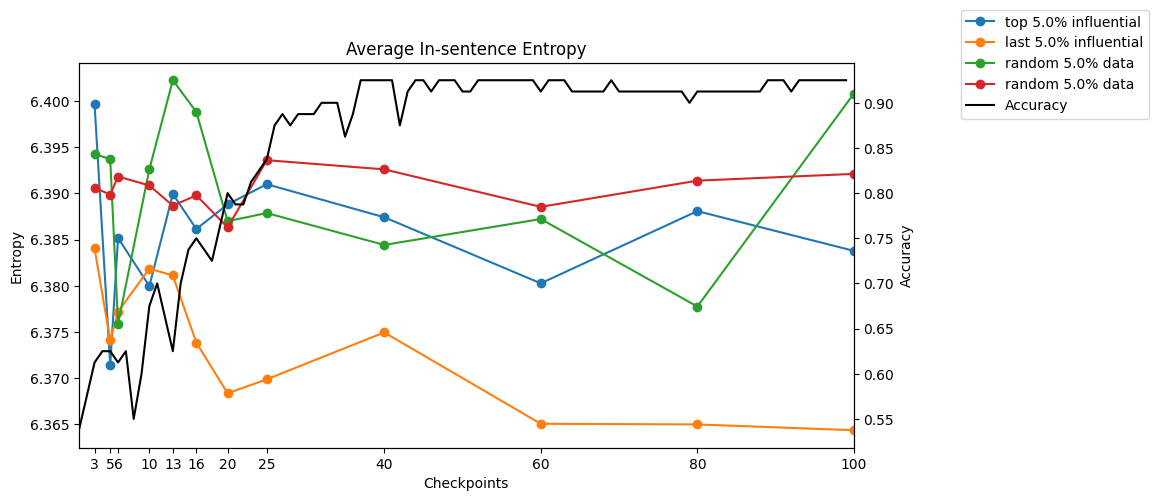

In [37]:
def inner_entropy(sentence_embed):
    mean_embed = sentence_embed[0, :]
    probabilities = torch.nn.functional.softmax(torch.tensor(mean_embed), dim=0).numpy()
    inner_entropy = entropy(probabilities)
    return inner_entropy

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))


topinf_entropies = []
for ckpt, ckpt_embeds in enumerate(top_ckpts_embeds):
    embed_entropies = [inner_entropy(embed[0]) for embed in ckpt_embeds]
    topinf_entropies.append(np.mean(embed_entropies))
ax1.plot(checkpoint_labels, topinf_entropies, 'o-', label=f"top {p*100}% influential")

lastinf_entropies = []
for ckpt_embeds in last_ckpts_embeds:
    embed_entropies = [inner_entropy(embed[0]) for embed in ckpt_embeds]
    lastinf_entropies.append(np.mean(embed_entropies))
ax1.plot(checkpoint_labels, lastinf_entropies, 'o-', label=f"last {p*100}% influential")

rand_entropies = []
for ckpt_embeds in random_embeds:
    rand_embed_entropies = [inner_entropy(embed[0]) for embed in ckpt_embeds]
    rand_entropies.append(np.mean(rand_embed_entropies))

ax1.plot(checkpoint_labels, rand_entropies, 'o-', label=f"random {p*100}% data")

rand_entropies = []
for ckpt_embeds in random_embeds_large:
    rand_embed_entropies = [inner_entropy(embed[0]) for embed in ckpt_embeds]
    rand_entropies.append(np.mean(rand_embed_entropies))

ax1.plot(checkpoint_labels, rand_entropies, 'o-', label=f"random {p*100}% data")


plt.title("Average In-sentence Entropy")
ax1.set_xlabel("Checkpoints")
ax1.set_ylabel("Entropy")
ax1.set_xticks(checkpoint_labels)
ax2 = ax1.twinx()
ax2.set_ylabel("Accuracy")
ax2.plot(accuracies, label="Accuracy", color='k')

fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()


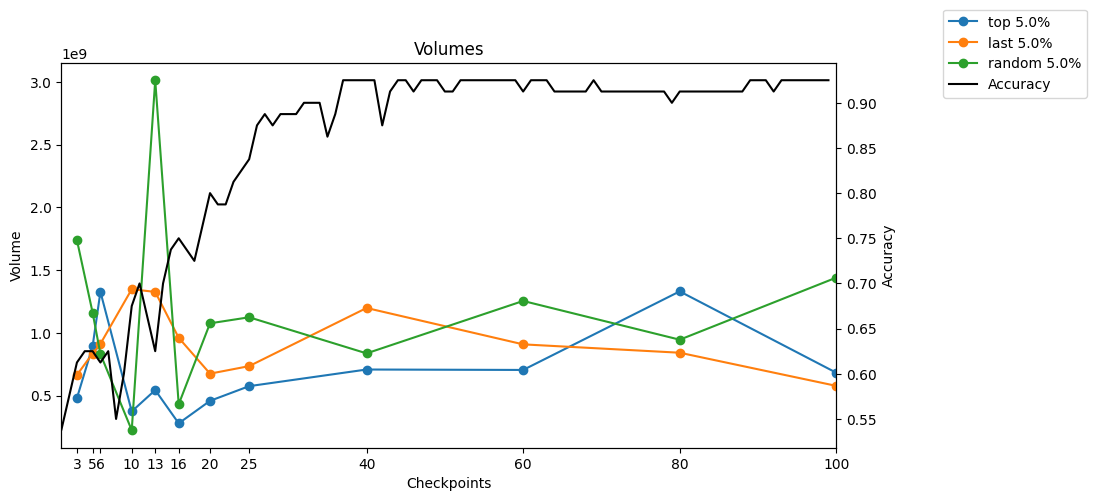

In [38]:
from sklearn.decomposition import PCA

def volume(sentences_embeds):
    return np.sqrt(np.linalg.det(sentences_embeds.T@sentences_embeds))

def pca(x, k):
    x_std = (x - np.mean(x, axis=0)) / (np.std(x, axis=0) + 1e-8)
    pca = PCA(n_components=k)
    pca.fit(x_std)
    return pca.components_

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))
label = ["top", "last", "random"]
for i, embeds in enumerate([top_ckpts_embeds, last_ckpts_embeds, random_embeds]):
    volumes = []
    for ckpt_embeds in embeds:
        mean_embeds = np.array([embed[0] for embed in ckpt_embeds])[:, 0, :]
        W = pca(mean_embeds, 10)
        Z_embeds = mean_embeds @ W.T
        volumes.append(volume(Z_embeds))
    ax1.plot(checkpoint_labels, volumes, 'o-', label=f"{label[i]} {p*100}%")
    

plt.title("Volumes")
ax1.set_xlabel("Checkpoints")
ax1.set_ylabel("Volume")
ax1.set_xticks(checkpoint_labels)
ax2 = ax1.twinx()
ax2.set_ylabel("Accuracy")
ax2.plot(accuracies, label="Accuracy", color='k')

fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

Top influential points have higher volume than least influential points

Checkpoint loaded at epoch 3 with completion rate 0.03
Checkpoint loaded at epoch 5 with completion rate 0.05
Checkpoint loaded at epoch 6 with completion rate 0.06
Checkpoint loaded at epoch 10 with completion rate 0.1
Checkpoint loaded at epoch 13 with completion rate 0.13
Checkpoint loaded at epoch 16 with completion rate 0.16
Checkpoint loaded at epoch 20 with completion rate 0.2
Checkpoint loaded at epoch 25 with completion rate 0.25
Checkpoint loaded at epoch 40 with completion rate 0.4
Checkpoint loaded at epoch 60 with completion rate 0.6
Checkpoint loaded at epoch 80 with completion rate 0.8
Checkpoint loaded at epoch 100 with completion rate 1.0
Checkpoint loaded at epoch 3 with completion rate 0.03
Checkpoint loaded at epoch 5 with completion rate 0.05
Checkpoint loaded at epoch 6 with completion rate 0.06
Checkpoint loaded at epoch 10 with completion rate 0.1
Checkpoint loaded at epoch 13 with completion rate 0.13
Checkpoint loaded at epoch 16 with completion rate 0.16
Chec

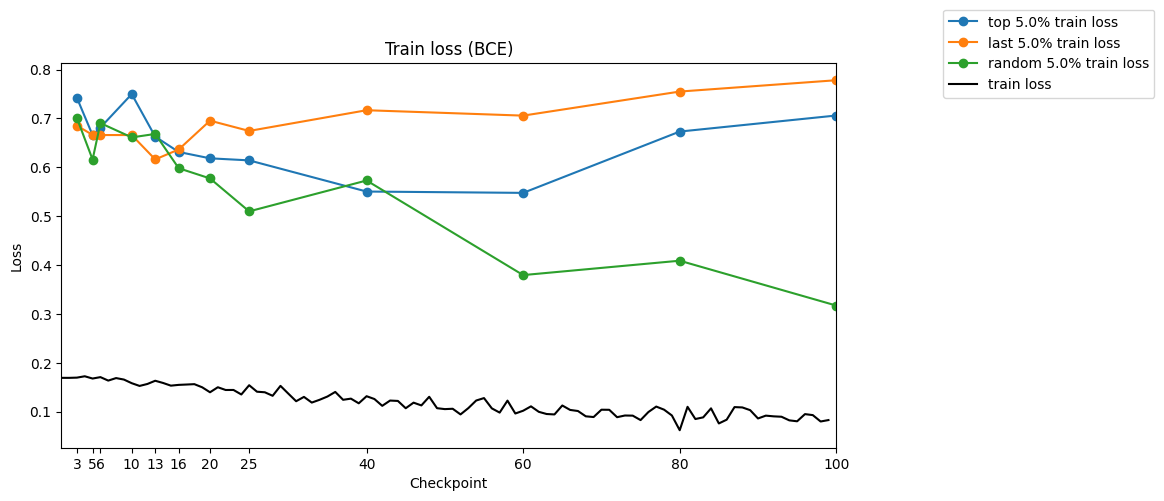

In [42]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))
labels = ["top", "last", "random"]
for j, ckpts_embeds in enumerate([top_ckpts_embeds, last_ckpts_embeds, random_embeds]):
    train_losses = [] # CrossEntropy loss
    for i, embeds in enumerate(ckpts_embeds):
        checkpoint = checkpoints[i]
        inputs = torch.tensor([embed[0] for embed in embeds], dtype=torch.float32, device=device).unsqueeze(1)
        expect_val = torch.tensor([embed[1] for embed in embeds], device=device)
        optimizer = torch.optim.Adam(TextCNN().parameters(), lr=0.0001)
        model, optimizer, _, _ = load_checkpoint(TextCNN().to(device), optimizer, checkpoint)
        loss_fn = nn.CrossEntropyLoss()
        outputs = model(inputs)
        loss = loss_fn(outputs, expect_val)
        train_losses.append(loss.item())
    ax1.plot(checkpoint_labels, train_losses, 'o-', 
             label=f"{labels[j]} {p*100}% train loss")

plt.title("Train loss (BCE)")
ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("Loss")
ax1.set_xticks(checkpoint_labels)
train_losses = torch.load("../influences/sst2/sst2_train_losses.pt")
ax1.plot(train_losses, label="train loss", color='k')

fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

Checkpoint loaded at epoch 3 with completion rate 0.03
Checkpoint loaded at epoch 5 with completion rate 0.05
Checkpoint loaded at epoch 6 with completion rate 0.06
Checkpoint loaded at epoch 10 with completion rate 0.1
Checkpoint loaded at epoch 13 with completion rate 0.13
Checkpoint loaded at epoch 16 with completion rate 0.16
Checkpoint loaded at epoch 20 with completion rate 0.2
Checkpoint loaded at epoch 25 with completion rate 0.25
Checkpoint loaded at epoch 40 with completion rate 0.4
Checkpoint loaded at epoch 60 with completion rate 0.6
Checkpoint loaded at epoch 80 with completion rate 0.8
Checkpoint loaded at epoch 100 with completion rate 1.0
Checkpoint loaded at epoch 3 with completion rate 0.03
Checkpoint loaded at epoch 5 with completion rate 0.05
Checkpoint loaded at epoch 6 with completion rate 0.06
Checkpoint loaded at epoch 10 with completion rate 0.1
Checkpoint loaded at epoch 13 with completion rate 0.13
Checkpoint loaded at epoch 16 with completion rate 0.16
Chec

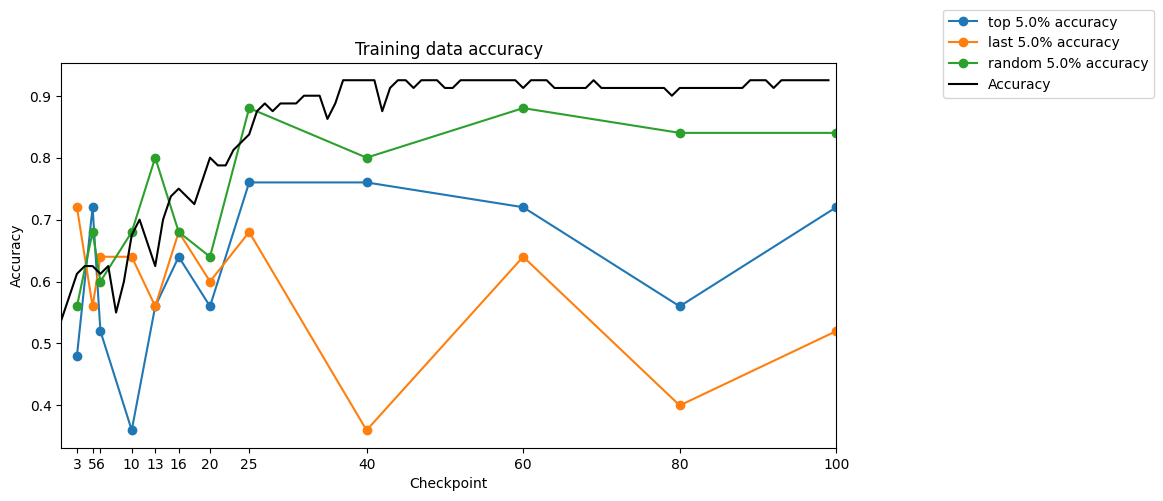

In [40]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))

labels = ["top", "last", "random"]
for j, ckpts_embeds in enumerate([top_ckpts_embeds, last_ckpts_embeds, random_embeds]):
    accuracies = []
    
    for i, embeds in enumerate(ckpts_embeds):
        checkpoint = checkpoints[i]
        inputs = torch.tensor([embed[0] for embed in embeds], dtype=torch.float32, device=device).unsqueeze(1)
        expect_val = torch.tensor([embed[1] for embed in embeds], device=device)
        model, optimizer, _, _ = load_checkpoint(TextCNN().to(device), optimizer, checkpoint)
        outputs = model(inputs)
        predictions = torch.argmax(outputs, dim=-1)
        accuracy = (predictions == expect_val).sum() / len(expect_val)
        accuracies.append(accuracy)
    ax1.plot(checkpoint_labels, accuracies, 'o-', 
             label=f"{labels[j]} {p*100}% accuracy")

plt.title("Training data accuracy")
ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("Accuracy")
ax1.set_xticks(checkpoint_labels)
accuracies = torch.load("../influences/sst2/sst2_accuracies.pt")
ax1.plot(accuracies, label="Accuracy", color='k')

fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()